In [66]:
# libraries 
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping

In [67]:
#data paths 
base_dir = "/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images"


In [68]:
train_dir = os.path.join(base_dir, "train")
test_dir = os.path.join(base_dir, "test")
val_dir = os.path.join(base_dir, "validation")

In [69]:
train_dir , test_dir , val_dir

('/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/train',
 '/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test',
 '/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/validation')

In [70]:
#count
def count_images(folder_path):
    counts = {}
    for class_name in os.listdir(folder_path):
        class_path = os.path.join(folder_path, class_name)
        if os.path.isdir(class_path):
            counts[class_name] = len(os.listdir(class_path))
    return counts

    

In [71]:
train_counts = count_images(train_dir)
test_counts = count_images(test_dir)
val_counts = count_images(val_dir)

In [72]:
train_counts

{'Bean': 1000,
 'Bitter_Gourd': 1000,
 'Bottle_Gourd': 1000,
 'Brinjal': 1000,
 'Broccoli': 1000,
 'Cabbage': 1000,
 'Capsicum': 1000,
 'Carrot': 1000,
 'Cauliflower': 1000,
 'Cucumber': 1000,
 'Papaya': 1000,
 'Potato': 1000,
 'Pumpkin': 1000,
 'Radish': 1000,
 'Tomato': 1000}

In [73]:
test_counts

{'Bean': 200,
 'Bitter_Gourd': 200,
 'Bottle_Gourd': 200,
 'Brinjal': 200,
 'Broccoli': 200,
 'Cabbage': 200,
 'Capsicum': 200,
 'Carrot': 200,
 'Cauliflower': 200,
 'Cucumber': 200,
 'Papaya': 200,
 'Potato': 200,
 'Pumpkin': 200,
 'Radish': 200,
 'Tomato': 200}

In [74]:
val_counts

{'Bean': 200,
 'Bitter_Gourd': 200,
 'Bottle_Gourd': 200,
 'Brinjal': 200,
 'Broccoli': 200,
 'Cabbage': 200,
 'Capsicum': 200,
 'Carrot': 200,
 'Cauliflower': 200,
 'Cucumber': 200,
 'Papaya': 200,
 'Potato': 200,
 'Pumpkin': 200,
 'Radish': 200,
 'Tomato': 200}

In [76]:
#df
train_df = pd.DataFrame(list(train_counts.items()), columns=["Vegetable", "Train Count"])
test_df = pd.DataFrame(list(test_counts.items()), columns=["Vegetable", "Test Count"])
val_df = pd.DataFrame(list(val_counts.items()), columns=["Vegetable", "Validation Count"])

In [77]:
summary_df = train_df.merge(test_df, on="Vegetable").merge(val_df, on="Vegetable")

In [78]:
summary_df

,Vegetable,Train Count,Test Count,Validation Count
0,Bean,1000,200,200
1,Bitter_Gourd,1000,200,200
2,Bottle_Gourd,1000,200,200
3,Brinjal,1000,200,200
4,Broccoli,1000,200,200
5,Cabbage,1000,200,200
6,Capsicum,1000,200,200
7,Carrot,1000,200,200
8,Cauliflower,1000,200,200
9,Cucumber,1000,200,200


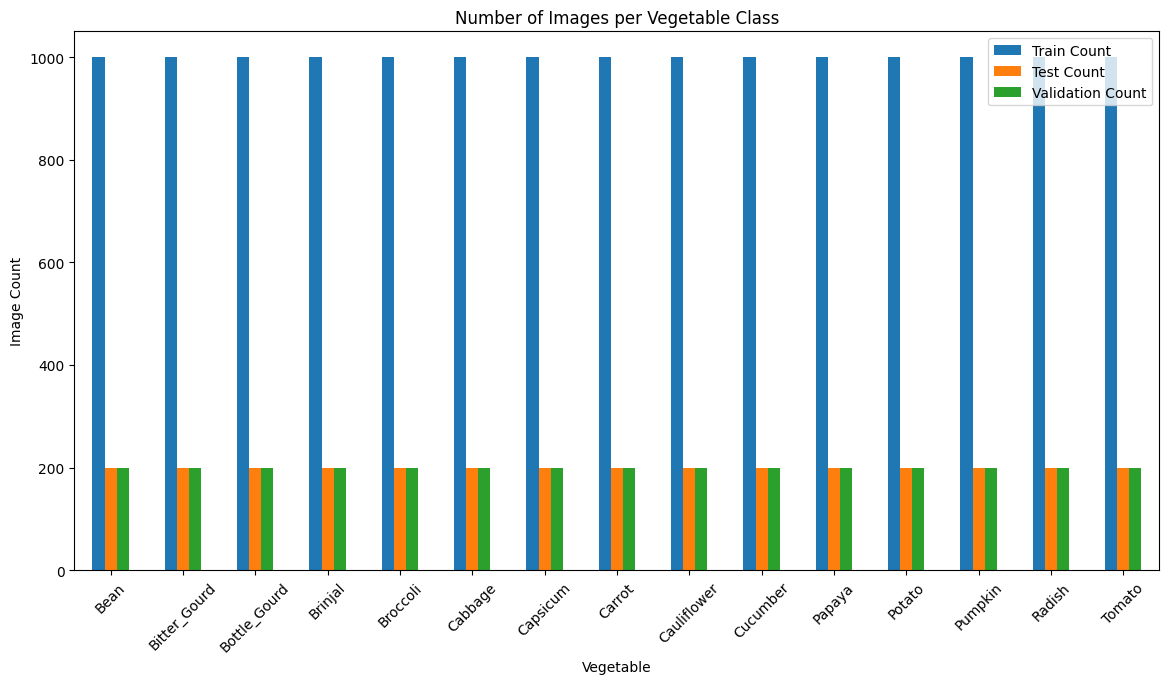

In [79]:
# visualization
summary_df.set_index("Vegetable").plot(kind="bar", figsize=(14, 7))

plt.title("Number of Images per Vegetable Class")
plt.xlabel("Vegetable")
plt.ylabel("Image Count")
plt.xticks(rotation=45)
plt.legend()
plt.show()


In [80]:
# the data is balanced every class in every split 1000 images 800 train and 200 test -- all are the same 

In [81]:
# img processing 
train_gen = ImageDataGenerator(
    rescale=1./255,rotation_range=20,width_shift_range=0.2,
    height_shift_range=0.2,shear_range=0.2,zoom_range=0.2,
    horizontal_flip=True,validation_split=0.2)

In [82]:
val_gen = ImageDataGenerator(rescale=1./255,validation_split=0.2)

In [83]:
# load images 
train_ds = train_gen.flow_from_directory(
    train_dir,target_size=(224, 224),batch_size=32,
    class_mode="categorical",subset="training",seed=42)

Found 12000 images belonging to 15 classes.


In [84]:
val_ds = val_gen.flow_from_directory(
    train_dir,target_size=(224, 224),batch_size=32,
    class_mode="categorical",subset="validation",seed=42)

Found 3000 images belonging to 15 classes.


In [86]:
train_ds.class_indices

{'Bean': 0,
 'Bitter_Gourd': 1,
 'Bottle_Gourd': 2,
 'Brinjal': 3,
 'Broccoli': 4,
 'Cabbage': 5,
 'Capsicum': 6,
 'Carrot': 7,
 'Cauliflower': 8,
 'Cucumber': 9,
 'Papaya': 10,
 'Potato': 11,
 'Pumpkin': 12,
 'Radish': 13,
 'Tomato': 14}

In [87]:
# cnn model 
model = Sequential([
    
    Conv2D(32, (3, 3), activation="relu", input_shape=(224, 224, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(512, activation="relu"),
    Dropout(0.5),
    Dense(15, activation="softmax")
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [88]:
# compile
model.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

In [89]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,403,791 (169.39 MB)

 Trainable params: 44,403,791 (169.39 MB)

 Non-trainable params: 0 (0.00 B)

In [90]:
## Conv layers: 3 (32, 64, 128 filters).
## Pooling: reduces the feature map size and keeps only the important features.
## Dropout: randomly turns off 50% of neurons to reduce the overfitting.
## Softmax: turns the outputs to probabilities for the 15 classes.

In [91]:
# training model 

early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=[early_stop])

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 500s 1s/step - accuracy: 0.4553 - loss: 1.6247 - val_accuracy: 0.7467 - val_loss: 0.7975
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 172s 458ms/step - accuracy: 0.7074 - loss: 0.8836 - val_accuracy: 0.8483 - val_loss: 0.4409
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 173s 462ms/step - accuracy: 0.7809 - loss: 0.6843 - val_accuracy: 0.8360 - val_loss: 0.5004
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 167s 445ms/step - accuracy: 0.8261 - loss: 0.5516 - val_accuracy: 0.9130 - val_loss: 0.2742
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 171s 457ms/step - accuracy: 0.8581 - loss: 0.4568 - val_accuracy: 0.8990 - val_loss: 0.3077
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 175s 465ms/step - accuracy: 0.8647 - loss: 0.4231 - val_accuracy: 0.8343 - val_loss: 0.4886
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 172s 459ms/step - accuracy: 0.8819 - loss: 0.3758 - val_accuracy: 0.9423 - val_loss: 0.1824
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 167s 444ms/step - accuracy: 0.8965 - lo

In [92]:
best_epoch = np.argmin(history.history["val_loss"]) + 1
print("Best epoch:", best_epoch)


Best epoch: 17


In [94]:
# Early stopping is good for saving time and prevent overfitting from the model to save the data during training 

In [95]:
#evaluate the model 
train_loss, train_acc = model.evaluate(train_ds)
val_loss, val_acc = model.evaluate(val_ds)

375/375 ━━━━━━━━━━━━━━━━━━━━ 157s 418ms/step - accuracy: 0.9643 - loss: 0.1138
94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 90ms/step - accuracy: 0.9823 - loss: 0.0691


In [96]:
print(f'Training Accuracy: {round(train_acc, 4)}')
print(f'Validation Accuracy: {round(val_acc, 4)}')
print(f'Training Loss: {round(train_loss, 4)}')
print(f'Validation Loss: {round(val_loss, 4)}')

Training Accuracy: 0.9643
Validation Accuracy: 0.9823
Training Loss: 0.1138
Validation Loss: 0.0691


In [97]:
# if the training accuracy is high and validation accuracy is low -  this means overfitting and the model memorizes the data 

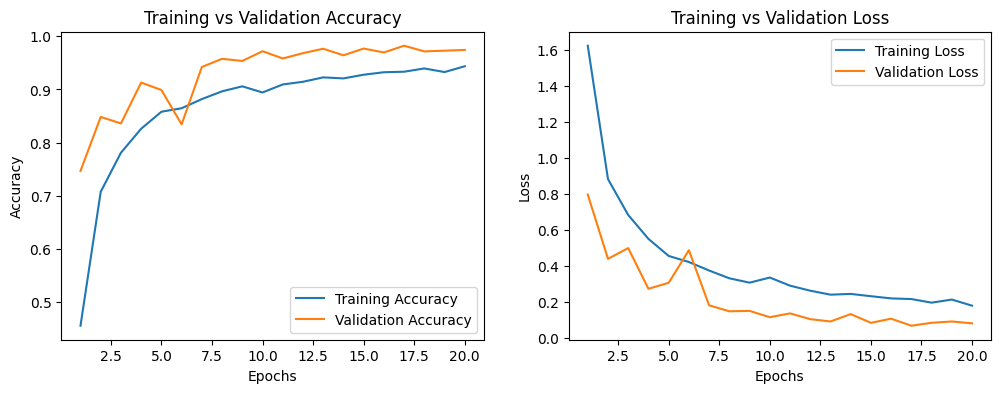

In [98]:
#plot acc / loss plot 
epochs_range = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(12, 4))

# accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history["accuracy"], label="Training Accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# loss plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history["loss"], label="Training Loss")
plt.plot(epochs_range, history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.show()
